# Tugas 2: Klasifikasi Teks SMS Spam/Ham Menggunakan Naive Bayes

Praktikum Klasifikasi - Pembelajaran Mesin
Perbandingan ekstraksi fitur CountVectorizer vs TF-IDF pada Multinomial Naive Bayes.


## 1. Load dan Persiapan Data


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Baca dataset dengan encoding latin-1
df = pd.read_csv('spam.csv', encoding='latin-1')

# Hapus kolom yang tidak diperlukan (Unnamed: 2, 3, 4)
df = df.drop(df.iloc[:, 2:], axis=1)

# Rename nama kolom
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

# Mapping label: spam = 1, ham = 0
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

df.head()


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
# Pisahkan fitur dan target
X = df['SMS'].to_numpy()
y = df['Labels'].to_numpy()

# Split data 80% train, 20% test (random_state=50 sesuai praktikum)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

print(f'Total data train: {len(X_train_raw)}')
print(f'Total data test : {len(X_test_raw)}')


Total data train: 4457
Total data test : 1115


---
## 2. Model 1: Multinomial Naive Bayes + CountVectorizer (stop_words='english')


In [3]:
# Ekstraksi fitur CountVectorizer dengan stop_words='english'
cv = CountVectorizer(stop_words='english')

X_train_cv = cv.fit_transform(X_train_raw)
X_test_cv = cv.transform(X_test_raw)

print(f'Jumlah vocab: {len(cv.get_feature_names_out())}')
print(f'Dimensi data train: {X_train_cv.shape}')
print(f'Dimensi data test : {X_test_cv.shape}')


Jumlah vocab: 7466
Dimensi data train: (4457, 7466)
Dimensi data test : (1115, 7466)


In [4]:
# Inisialisasi dan training model MNB
mnb_cv = MultinomialNB()
mnb_cv.fit(X_train_cv, y_train)

# Prediksi data train & test
y_pred_train_cv = mnb_cv.predict(X_train_cv)
y_pred_test_cv = mnb_cv.predict(X_test_cv)

# Hitung akurasi
acc_train_cv = accuracy_score(y_train, y_pred_train_cv)
acc_test_cv = accuracy_score(y_test, y_pred_test_cv)

print(f'Akurasi Train (CountVectorizer): {acc_train_cv:.4f} ({acc_train_cv*100:.2f}%)')
print(f'Akurasi Test  (CountVectorizer): {acc_test_cv:.4f} ({acc_test_cv*100:.2f}%)')


Akurasi Train (CountVectorizer): 0.9946 (99.46%)
Akurasi Test  (CountVectorizer): 0.9830 (98.30%)


=== Classification Report: CountVectorizer ===
              precision    recall  f1-score   support

     Ham (0)     0.9835    0.9969    0.9901       954
    Spam (1)     0.9797    0.9006    0.9385       161

    accuracy                         0.9830      1115
   macro avg     0.9816    0.9487    0.9643      1115
weighted avg     0.9829    0.9830    0.9827      1115



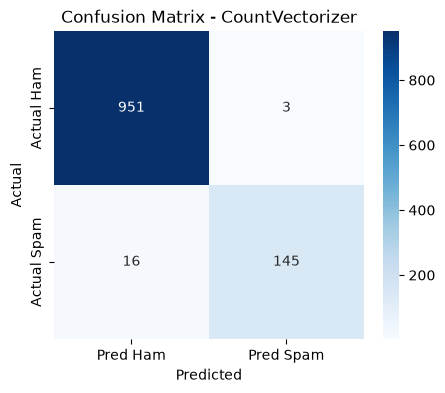

In [5]:
# Evaluasi detail: Classification Report & Confusion Matrix
print('=== Classification Report: CountVectorizer ===')
print(classification_report(y_test, y_pred_test_cv, target_names=['Ham (0)', 'Spam (1)'], digits=4))

cm_cv = confusion_matrix(y_test, y_pred_test_cv)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Ham', 'Pred Spam'],
            yticklabels=['Actual Ham', 'Actual Spam'])
plt.title('Confusion Matrix - CountVectorizer')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


---
## 3. Model 2: Multinomial Naive Bayes + TF-IDF (stop_words='english')


In [6]:
# Ekstraksi fitur TfidfVectorizer dengan stop_words='english'
tfidf = TfidfVectorizer(stop_words='english')

X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_test_tfidf = tfidf.transform(X_test_raw)

print(f'Jumlah vocab: {len(tfidf.get_feature_names_out())}')
print(f'Dimensi data train: {X_train_tfidf.shape}')
print(f'Dimensi data test : {X_test_tfidf.shape}')


Jumlah vocab: 7466
Dimensi data train: (4457, 7466)
Dimensi data test : (1115, 7466)


In [7]:
# Inisialisasi dan training model MNB
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)

# Prediksi data train & test
y_pred_train_tfidf = mnb_tfidf.predict(X_train_tfidf)
y_pred_test_tfidf = mnb_tfidf.predict(X_test_tfidf)

# Hitung akurasi
acc_train_tfidf = accuracy_score(y_train, y_pred_train_tfidf)
acc_test_tfidf = accuracy_score(y_test, y_pred_test_tfidf)

print(f'Akurasi Train (TF-IDF): {acc_train_tfidf:.4f} ({acc_train_tfidf*100:.2f}%)')
print(f'Akurasi Test  (TF-IDF): {acc_test_tfidf:.4f} ({acc_test_tfidf*100:.2f}%)')


Akurasi Train (TF-IDF): 0.9843 (98.43%)
Akurasi Test  (TF-IDF): 0.9605 (96.05%)


=== Classification Report: TF-IDF ===
              precision    recall  f1-score   support

     Ham (0)     0.9559    1.0000    0.9775       954
    Spam (1)     1.0000    0.7267    0.8417       161

    accuracy                         0.9605      1115
   macro avg     0.9780    0.8634    0.9096      1115
weighted avg     0.9623    0.9605    0.9579      1115



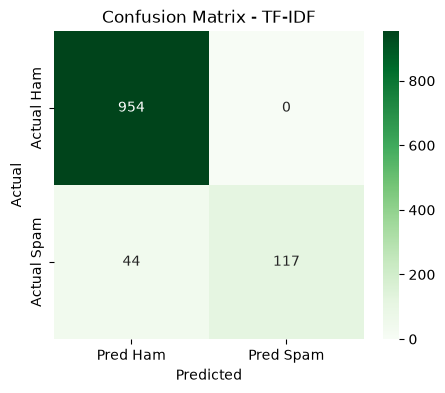

In [8]:
# Evaluasi detail: Classification Report & Confusion Matrix
print('=== Classification Report: TF-IDF ===')
print(classification_report(y_test, y_pred_test_tfidf, target_names=['Ham (0)', 'Spam (1)'], digits=4))

cm_tfidf = confusion_matrix(y_test, y_pred_test_tfidf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_tfidf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Pred Ham', 'Pred Spam'],
            yticklabels=['Actual Ham', 'Actual Spam'])
plt.title('Confusion Matrix - TF-IDF')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


---
## 4. Perbandingan Hasil dan Evaluasi


In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Rangkum metrik ke DataFrame
summary_data = {
    'Metode': ['CountVectorizer', 'TF-IDF'],
    'Akurasi Train': [acc_train_cv, acc_train_tfidf],
    'Akurasi Test': [acc_test_cv, acc_test_tfidf],
    'Precision (Spam)': [
        precision_score(y_test, y_pred_test_cv, pos_label=1),
        precision_score(y_test, y_pred_test_tfidf, pos_label=1)
    ],
    'Recall (Spam)': [
        recall_score(y_test, y_pred_test_cv, pos_label=1),
        recall_score(y_test, y_pred_test_tfidf, pos_label=1)
    ],
    'F1-Score (Spam)': [
        f1_score(y_test, y_pred_test_cv, pos_label=1),
        f1_score(y_test, y_pred_test_tfidf, pos_label=1)
    ]
}

df_summary = pd.DataFrame(summary_data)
df_summary


,Metode,Akurasi Train,Akurasi Test,Precision (Spam),Recall (Spam),F1-Score (Spam)
0,CountVectorizer,0.994615,0.982960,0.97973,0.900621,0.938511
1,TF-IDF,0.984294,0.960538,1.00000,0.726708,0.841727


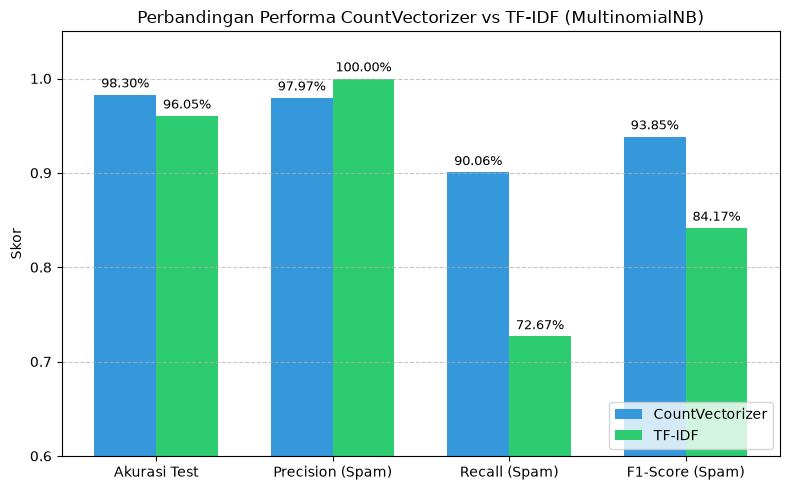

In [10]:
# Visualisasi perbandingan metrik evaluasi
metrics = ['Akurasi Test', 'Precision (Spam)', 'Recall (Spam)', 'F1-Score (Spam)']
cv_vals = df_summary.loc[0, metrics].values
tfidf_vals = df_summary.loc[1, metrics].values

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, cv_vals, width, label='CountVectorizer', color='#3498db')
rects2 = ax.bar(x + width/2, tfidf_vals, width, label='TF-IDF', color='#2ecc71')

ax.set_ylabel('Skor')
ax.set_title('Perbandingan Performa CountVectorizer vs TF-IDF (MultinomialNB)')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0.6, 1.05)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.2%}',
                xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


---
## 5. Kesimpulan

Dari hasil perbandingan pada dataset spam.csv menggunakan Multinomial Naive Bayes:

1. CountVectorizer unggul secara keseluruhan
Akurasi data test mencapai 98.30 persen, lebih tinggi dibanding TF-IDF yang dapat 96.05 persen. F1-score untuk deteksi spam juga mencapai 93.85 persen, jauh lebih baik dibanding TF-IDF yang cuma 84.17 persen.

2. Kelebihan dan kekurangan masing-masing
TF-IDF punya precision spam 100 persen, jadi tidak ada SMS normal yang salah dituduh spam. Tapi kelemahannya ada di recall yang anjlok ke 72.67 persen, artinya ada 44 SMS spam yang gagal ditangkap dan lolos ke inbox.
Sementara CountVectorizer jauh lebih seimbang dengan recall 90.06 persen dan precision 97.97 persen. Cuma 16 spam yang lolos dan cuma 3 SMS normal yang salah masuk spam.

3. Alasan teknis
Pesan SMS itu rata-rata pendek dan kata-katanya jarang berulang di satu pesan. Untuk teks pendek, hitungan kata biasa pada CountVectorizer bekerja lebih pas dengan model Multinomial Naive Bayes. Sedangkan pembobotan nilai desimal pada TF-IDF malah bikin probabilitas kata spam mengecil, sehingga modelnya jadi terlalu ragu menebak spam.

Kesimpulan: Fitur terbaik untuk klasifikasi SMS spam ini adalah CountVectorizer.
